# Q15 – What should the "you may also like" shelf show, and to whom?
**Team 5 · New Media Technology and Analytics · Lumen Beauty (Sep–Nov 2026) · Association rules (Week 3)**

After every purchase, Lumen Beauty's mini-program shows a "you may also like" shelf. This notebook mines association rules on **single orders** and on **whole customer histories**, reports every rule with its **co-purchase count and denominator**, checks whom each shelf would serve (light vs heavy buyers), and translates the shippable rules into **shelf decisions** with an explicit **kill condition**.


## 0 · Setup
We use the same tools as the Week 3 notebook: **pandas** for the tables, **matplotlib** for charts, and **mlxtend** to find the rules. mlxtend must be version **0.23.4 or newer**.

Charts for the report and pitch are saved under `figures/` as we go.


In [1]:
import warnings
from pathlib import Path

import pandas as pd                    # tables
import matplotlib.pyplot as plt        # EDA + finding charts
import numpy as np
import mlxtend
from mlxtend.preprocessing import TransactionEncoder               # turns each basket into a yes/no table
from mlxtend.frequent_patterns import apriori, association_rules   # finds frequent pairs and turns them into rules

warnings.filterwarnings("ignore", category=DeprecationWarning)   # hide technical warnings that do not change the results (as in W03)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Chart style for the report / pitch (calm, analytical — not purple defaults)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5A6472",
    "axes.labelcolor": "#1C242E",
    "xtick.color": "#5A6472",
    "ytick.color": "#5A6472",
    "text.color": "#1C242E",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
INK, MUTED, ACCENT, WARM, LIGHT = "#1C242E", "#5A6472", "#0F6B5C", "#C2410C", "#9AA5B1"

print("pandas", pd.__version__, "| mlxtend", mlxtend.__version__)   # the versions used in this run


pandas 3.1.1 | mlxtend 0.25.0


## 1 · First look: open the files, meet the data  *(W02)*
We use two of the five project tables: **lb_order_lines** (what was bought, in which order and by whom) and **lb_users** (how many orders each user placed). Nothing is cleaned yet: we only look. As in the BakeBox export, `lb_order_lines` has **one row per order line**: an order with three products takes three rows. To run this notebook, put lb_order_lines.csv and lb_users.csv in the same folder as the notebook (in the project kit they are in the data/ folder).

In [2]:
from pathlib import Path

DATA_CANDIDATES = [Path("data"), Path(".")]
data_dir = next((p for p in DATA_CANDIDATES if (p / "lb_order_lines.csv").exists()), Path("data"))
lines_path = data_dir / "lb_order_lines.csv"
users_path = data_dir / "lb_users.csv"
if not lines_path.exists():
    raise FileNotFoundError(
        "Place lb_order_lines.csv and lb_users.csv in ./data/ (course project kit). "
        f"Looked in: {[str(p.resolve()) for p in DATA_CANDIDATES]}"
    )

lines = pd.read_csv(lines_path)   # one row per product line of an order
users = pd.read_csv(users_path)   # one row per registered user
print("data dir:", data_dir.resolve())
print("order lines:", lines.shape, "| users:", users.shape)
lines.head()


data dir: /workspace/data
order lines: (4920, 10) | users: (1000, 9)


,order_id,user_id,sku_id,sku_name,category,qty,unit_price,channel,stream_id,order_date
0,O00001,U0009,LB21,Caffeine Eye Serum,Eye Care,1,181.19,livestream,S01,2026-09-01
1,O00002,U0020,LB23,Cooling Eye Gel,Eye Care,1,198.23,livestream,S01,2026-09-01
2,O00003,U0030,LB28,Tone-up Sunscreen,Sunscreen,1,130.07,livestream,S01,2026-09-01
3,O00004,U0034,LB28,Tone-up Sunscreen,Sunscreen,1,130.07,livestream,S01,2026-09-01
4,O00005,U0040,LB05,Barrier Repair Cream,Cream,1,226.63,livestream,S01,2026-09-01


In [3]:
# The size of the data: orders, buyers, products and dates
print("orders:", lines["order_id"].nunique(), "| buyers:", lines["user_id"].nunique(),
      "| SKUs:", lines["sku_id"].nunique(), "| categories:", lines["category"].nunique())
print("dates:", lines["order_date"].min(), "to", lines["order_date"].max())
print("registered users who never ordered:", (users["n_orders"] == 0).sum())

# The channel counted two ways: order lines, and whole orders (each order has one channel)
print("order lines by channel:", lines["channel"].value_counts().to_dict())
print("orders by channel:", lines.groupby("order_id")["channel"].first().value_counts().to_dict())

orders: 3401 | buyers: 647 | SKUs: 30 | categories: 8
dates: 2026-09-01 to 2026-11-30
registered users who never ordered: 353
order lines by channel: {'livestream': 3705, 'store': 1215}
orders by channel: {'livestream': 2579, 'store': 822}


**First look – what we see:**
- 4,920 order lines make 3,401 orders, placed by 647 buyers over the whole quarter (1 September to 30 November 2026). The other 353 registered users never ordered, so they cannot appear in any basket.
- The catalog has 30 products (SKUs) in 8 categories.
- Orders come through two channels only: **livestream** (2,579 orders) and **store** (822 orders). Values such as search, short_video and ad belong to another column, users.first_channel, which records how a user first arrived, not where they ordered. Our project plan had mixed the two up.

## 2 · Clean: duplicates → missing values → units → outliers *(W02)*
We follow the order of the Week 2 checklist: duplicates first, then missing values, units and outliers. Every fix is noted below the cell that makes it.

In [4]:
# Check 1 – Duplicates: rows identical in every column
print("exact duplicate rows:", lines.duplicated().sum())
lines[lines.duplicated(keep=False)].sort_values("order_id").head(6)

exact duplicate rows: 5


,order_id,user_id,sku_id,sku_name,category,qty,unit_price,channel,stream_id,order_date
1599,O01121,U0146,LB08,Brightening Cream,Cream,1,249.00,store,NaN,2026-09-30
1600,O01121,U0146,LB08,Brightening Cream,Cream,1,249.00,store,NaN,2026-09-30
3115,O02153,U0127,LB06,Peptide Firming Cream,Cream,1,240.35,livestream,S50,2026-10-28
3117,O02153,U0127,LB06,Peptide Firming Cream,Cream,1,240.35,livestream,S50,2026-10-28
3228,O02227,U0646,LB05,Barrier Repair Cream,Cream,1,399.00,store,NaN,2026-10-29
3230,O02227,U0646,LB05,Barrier Repair Cream,Cream,1,399.00,store,NaN,2026-10-29


In [5]:
lines = lines.drop_duplicates().reset_index(drop=True)   # keep one copy of each duplicated line
print("order lines after removing duplicates:", len(lines))
print(f"GMV after cleaning: ¥{(lines['qty'] * lines['unit_price']).sum():,.2f}")   # GMV = quantity x price, summed

order lines after removing duplicates: 4915
GMV after cleaning: ¥1,171,735.16


**Fix 1 – Duplicates:** 5 order lines appeared twice, identical in every column (for example, order O01121 lists the same Brightening Cream twice). They are export errors, as S07 in the Week 2 case, so we keep one copy of each: 4,915 lines remain. GMV after cleaning is ¥1,171,735; the project plan's ¥1,173,482 still counted the duplicates.

In [6]:
# Check 2 – Missing values, column by column
print("empty stream_id only on store lines:", (lines["stream_id"].isna() == (lines["channel"] == "store")).all())
lines.isna().sum()

empty stream_id only on store lines: True


order_id         0
user_id          0
sku_id           0
sku_name         0
category         0
qty              0
unit_price       0
channel          0
stream_id     1213
order_date       0
dtype: int64

**Check 2 – Missing values:** only stream_id is empty, on 1,213 lines, and always on store orders. These are not missing data: the data dictionary says that a store order has no stream. We keep them.

In [7]:
# Check 3 – Units: quantities and prices must be plausible
print("qty:", lines["qty"].min(), "to", lines["qty"].max(),
      "| unit_price: ¥", lines["unit_price"].min(), "to", lines["unit_price"].max())

# Each product has one fixed store price; livestream prices can move with promotions
store = lines[lines["channel"] == "store"]
print("different store prices per product (max):", store.groupby("sku_name")["unit_price"].nunique().max())
store_price = store.groupby("sku_name")["unit_price"].first()        # the store price of each product
ratio = lines["unit_price"] / lines["sku_name"].map(store_price)     # price paid / store price
print("price paid / store price:", round(ratio.min(), 2), "to", round(ratio.max(), 2))

qty: 1 to 2 | unit_price: ¥ 54.45 to 504.85
different store prices per product (max): 1
price paid / store price: 0.55 to 1.15


**Check 3 – Units:** quantities are 1 or 2 and prices go from ¥54 to ¥505, with no zero or negative values. Each product has one fixed store price, and every price paid sits between 0.55 and 1.15 times it: exactly the range the data dictionary gives for livestream promotions. No price was recorded in a wrong unit.

In [8]:
# Check 4 – Outliers: how many orders does each buyer place?
buyers = users.loc[users["n_orders"] > 0, "n_orders"]     # the 647 users who ordered
q1, q3 = buyers.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)                               # the usual boxplot limit for "too high"
print("orders per buyer:", buyers.min(), "to", buyers.max(), "| median:", buyers.median())
print("upper limit:", fence, "| buyers above it:", (buyers > fence).sum())

orders per buyer: 1 to 20 | median: 3.0
upper limit: 21.0 | buyers above it: 0


**Check 4 – Outliers:** buyers placed between 1 and 20 orders in the quarter (median 3). With the usual boxplot rule, a buyer would be an outlier above 21 orders, and nobody passes that limit. The heaviest buyers are real, and they are exactly the group our question is about, so we keep them all.

**Data ready:** 4,915 clean order lines, 3,401 orders and 647 buyers.

## 3 · Light, mid and heavy buyers
Q15 asks whether the shelf serves light or heavy buyers, so we split buyers by **n_orders**, the number of distinct orders each user placed in the quarter. The cut-offs are our choice, and each has a simple meaning:

| group | n_orders | meaning |
|---|---|---|
| light | 1–2 | tried the store once or twice (includes first-time buyers) |
| mid | 3–5 | about one order a month |
| heavy | 6 or more | about two orders a month or more |

Section 8a checks that the conclusion does not depend on these cut-offs.

In [9]:
n_lines = len(lines)
lines = lines.merge(users[["user_id", "n_orders"]], on="user_id")
assert len(lines) == n_lines   # every buyer is found in lb_users

counted = lines.groupby("user_id")["order_id"].nunique()
assert (counted == lines.groupby("user_id")["n_orders"].first()).all()   # n_orders matches the order table
print(counted.size, "buyers, all in lb_users; n_orders matches the order table for every buyer")
lines["buyer_type"] = pd.cut(lines["n_orders"], bins=[0, 2, 5, 99], labels=["light", "mid", "heavy"])

groups = lines.groupby("buyer_type", observed=True).agg(
    buyers=("user_id", "nunique"), orders=("order_id", "nunique"))
groups["% of buyers"] = (100 * groups["buyers"] / groups["buyers"].sum()).round(1)
groups["% of orders"] = (100 * groups["orders"] / groups["orders"].sum()).round(1)
groups

647 buyers, all in lb_users; n_orders matches the order table for every buyer


,buyers,orders,% of buyers,% of orders
buyer_type,,,,
light,301,366,46.5,10.8
mid,81,304,12.5,8.9
heavy,265,2731,41.0,80.3


**Results interpretation**

1. **WHO ARE THE BUYERS?** Almost half of the buyers (301, 46.5%) are light: they ordered once or twice. Heavy buyers are 265 (41%), and the mid group is small (81, 12.5%).
2. **WHO PLACES THE ORDERS?** Heavy buyers place **80% of all orders** (2,731 of 3,401), light buyers only 11%. A heavy buyer orders about 10 times in the quarter, a light buyer about once.
3. **WHY IT MATTERS:** any rule learned from these data hears heavy buyers far more than light ones. Sections 7 and 8 show what this does to rules built on whole histories; section 9 checks whether the main order rule still holds for light buyers.

## 4 · From order lines to baskets, two ways  *(W03 section 2)*
A **basket** is the set of distinct products. We build it two ways:
- **Order basket**: the products bought **together, in one order**. This is the moment the shelf appears.
- **History basket**: every product **one customer** bought in the whole quarter.

The only difference is the column we group by: `order_id` or `user_id`.

In [10]:
# Order baskets: the distinct products bought together in one order
orders = lines.groupby("order_id").agg(
    buyer_type=("buyer_type", "first"),                     # one order = one buyer, so one buyer type
    items=("sku_name", lambda s: sorted(set(s))),          # the products in the order, each counted once
    categories=("category", lambda s: sorted(set(s))),     # the same basket at category level
)
# History baskets: every distinct product one customer bought in the quarter
histories = lines.groupby("user_id").agg(
    buyer_type=("buyer_type", "first"),
    items=("sku_name", lambda s: sorted(set(s))),
)

# How big the baskets are
orders["n_items"] = orders["items"].apply(len)
histories["n_items"] = histories["items"].apply(len)
print(len(orders), "order baskets, average", round(orders["n_items"].mean(), 2), "products")
print(len(histories), "history baskets, average", round(histories["n_items"].mean(), 2), "products")
print("\nproducts per order:", orders["n_items"].value_counts().sort_index().to_dict())
orders.head()

3401 order baskets, average 1.45 products
647 history baskets, average 6.27 products

products per order: {1: 2219, 2: 850, 3: 332}


,buyer_type,items,categories,n_items
order_id,,,,
O00001,heavy,[Caffeine Eye Serum],[Eye Care],1
O00002,heavy,[Cooling Eye Gel],[Eye Care],1
O00003,heavy,[Tone-up Sunscreen],[Sunscreen],1
O00004,heavy,[Tone-up Sunscreen],[Sunscreen],1
O00005,heavy,"[Barrier Repair Cream, Pore Refining Toner]","[Cream, Toner]",2


**Results interpretation**

- **Order baskets are small:** 3,401 baskets with 1.45 distinct products on average, and **65% of orders contain one product only** (2,219 of 3,401). A one-product basket can never form a pair. (1.45 counts distinct products, not items: the qty column is ignored here.)
- **History baskets are more than four times bigger:** 647 baskets with 6.27 products on average, because each one adds up a whole quarter of orders.
- **Why it matters:** the bigger the basket, the more pairs it creates. This difference in size drives the gap between the two kinds of rules in sections 6 and 7.

## 4b · Exploratory charts *(before the rules)*
Before mining association rules, we look at the shape of the data: how big baskets are, who places the orders, which categories dominate, and where a cream add-on could still happen. These charts also feed the report and the pitch.


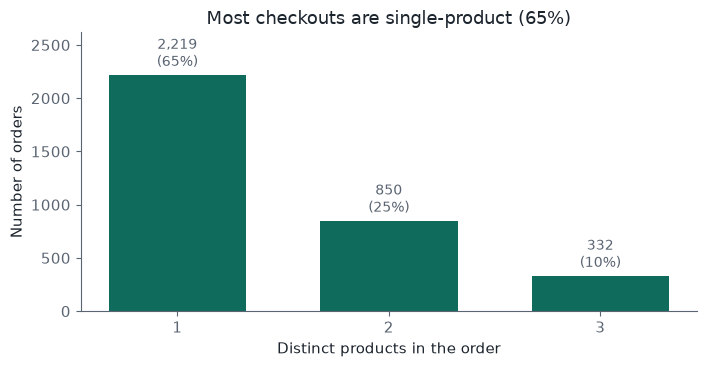

In [11]:
# Chart 1 — Basket size: most orders leave with a single product
size_counts = orders["n_items"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.2, 3.8))
bars = ax.bar(size_counts.index.astype(str), size_counts.values, color=ACCENT, width=0.65)
ax.set_xlabel("Distinct products in the order")
ax.set_ylabel("Number of orders")
ax.set_title("Most checkouts are single-product (65%)")
for b, n in zip(bars, size_counts.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 40, f"{n:,}\n({100*n/len(orders):.0f}%)",
            ha="center", va="bottom", fontsize=10, color=MUTED)
ax.set_ylim(0, size_counts.max() * 1.18)
fig.tight_layout()
fig.savefig(FIG / "fig_basket_size.png", dpi=160, bbox_inches="tight")
plt.show()


**EDA – basket size:** 2,219 of 3,401 orders (65%) contain one product only. Those baskets can never form a co-purchase pair on their own — they are exactly the moment the “you may also like” shelf can still add something.


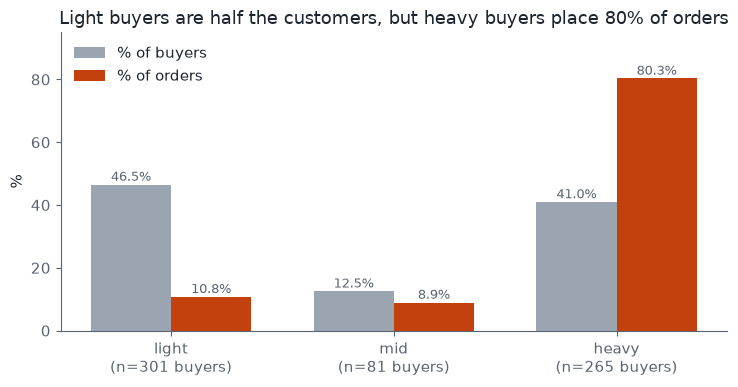

In [12]:
# Chart 2 — Who the buyers are vs who places the orders
g = lines.groupby("buyer_type", observed=True).agg(
    buyers=("user_id", "nunique"), orders=("order_id", "nunique"))
g["pct_buyers"] = 100 * g["buyers"] / g["buyers"].sum()
g["pct_orders"] = 100 * g["orders"] / g["orders"].sum()

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(g))
w = 0.36
ax.bar(x - w/2, g["pct_buyers"], width=w, color=LIGHT, label="% of buyers")
ax.bar(x + w/2, g["pct_orders"], width=w, color=WARM, label="% of orders")
ax.set_xticks(x)
ax.set_xticklabels([f"{i}\n(n={int(b)} buyers)" for i, b in zip(g.index, g["buyers"])])
ax.set_ylabel("%")
ax.set_title("Light buyers are half the customers, but heavy buyers place 80% of orders")
ax.legend(frameon=False)
for i, (pb, po) in enumerate(zip(g["pct_buyers"], g["pct_orders"])):
    ax.text(i - w/2, pb + 1.2, f"{pb:.1f}%", ha="center", fontsize=9, color=MUTED)
    ax.text(i + w/2, po + 1.2, f"{po:.1f}%", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, 95)
fig.tight_layout()
fig.savefig(FIG / "fig_buyers_vs_orders.png", dpi=160, bbox_inches="tight")
plt.show()


**EDA – intensity:** almost half of buyers are light (1–2 orders), but they place only ~11% of orders. Any rule learned from the full order table hears heavy buyers far more often — which is why Q15 asks “to whom?”


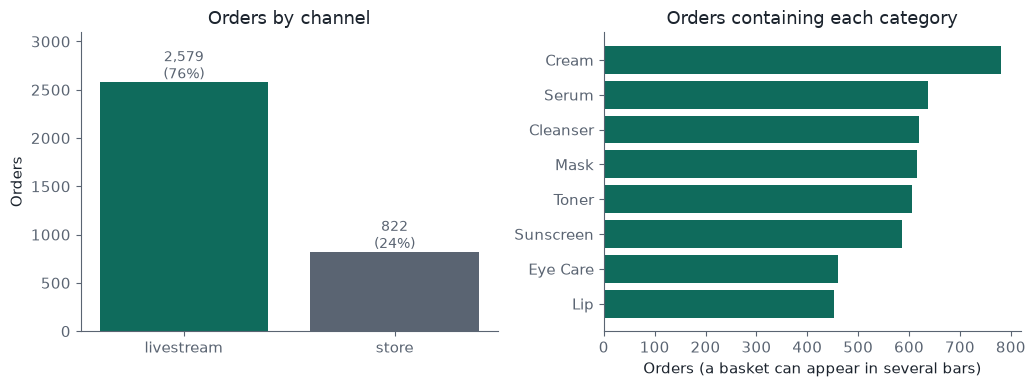

In [13]:
# Chart 3 — Channel mix and category mix (two panels)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))

ch = lines.groupby("order_id")["channel"].first().value_counts()
axes[0].bar(ch.index, ch.values, color=[ACCENT, MUTED])
axes[0].set_title("Orders by channel")
axes[0].set_ylabel("Orders")
for i, (lab, n) in enumerate(ch.items()):
    axes[0].text(i, n + 40, f"{n:,}\n({100*n/ch.sum():.0f}%)", ha="center", fontsize=10, color=MUTED)
axes[0].set_ylim(0, ch.max() * 1.2)

cat = lines.drop_duplicates(["order_id", "category"]).groupby("category")["order_id"].nunique().sort_values(ascending=True)
axes[1].barh(cat.index, cat.values, color=ACCENT)
axes[1].set_title("Orders containing each category")
axes[1].set_xlabel("Orders (a basket can appear in several bars)")
fig.tight_layout()
fig.savefig(FIG / "fig_channel_and_categories.png", dpi=160, bbox_inches="tight")
plt.show()


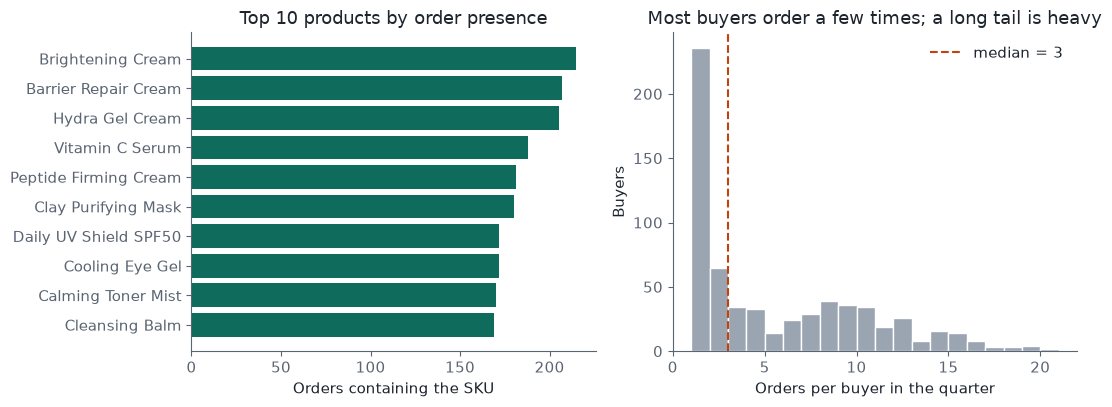

In [14]:
# Chart 4 — Top SKUs and orders-per-buyer distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

sku = lines.groupby("sku_name")["order_id"].nunique().sort_values(ascending=False).head(10)
axes[0].barh(sku.index[::-1], sku.values[::-1], color=ACCENT)
axes[0].set_xlabel("Orders containing the SKU")
axes[0].set_title("Top 10 products by order presence")

buyer_n = users.loc[users["n_orders"] > 0, "n_orders"]
axes[1].hist(buyer_n, bins=range(1, int(buyer_n.max()) + 2), color=LIGHT, edgecolor="white")
axes[1].axvline(buyer_n.median(), color=WARM, linestyle="--", label=f"median = {buyer_n.median():.0f}")
axes[1].set_xlabel("Orders per buyer in the quarter")
axes[1].set_ylabel("Buyers")
axes[1].set_title("Most buyers order a few times; a long tail is heavy")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_top_skus_and_frequency.png", dpi=160, bbox_inches="tight")
plt.show()


**EDA – catalogue & frequency:** serums and creams are among the most present categories; the buyer-frequency histogram shows the long tail of heavy buyers that will later dominate history-based rules.


## 5 · One function for the Week 3 steps *(W03)*
In Week 3, finding rules took three steps: turn each basket into a yes/no table, find the pairs that appear often enough (Apriori), and turn them into rules. The function `mine()` does the three steps in one go, so we can reuse it in every section. It only looks at **pairs** of products, because the shelf shows one product next to another.

In [15]:
# Write a rule as readable text, e.g. "Vitamin C Serum -> Hydra Gel Cream"
def rule_text(a, c):
    return " + ".join(sorted(a)) + " -> " + " + ".join(sorted(c))

# The three Week 3 steps in one function.
# Support/confidence filter observed frequency — they are not significance tests.
# Every rule table we print also carries co-purchase count and its denominator.
def mine(baskets, min_support, denom_label="baskets"):
    # 1. yes/no table: one row per basket, one column per product
    te = TransactionEncoder()
    onehot = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
    n = len(onehot)
    # 2. products and pairs found in enough baskets (pairs only: max_len=2)
    frequent = apriori(onehot, min_support=min_support, use_colnames=True, max_len=2)
    # 3. rules with support, confidence and lift
    rules = association_rules(frequent, metric="confidence", min_threshold=0.0)
    rules["rule"] = [rule_text(a, c) for a, c in zip(rules["antecedents"], rules["consequents"])]
    rules["both"] = (rules["support"] * n).round().astype(int)
    rules["denom"] = n
    rules["antecedent_count"] = (rules["antecedent support"] * n).round().astype(int)
    rules["denom_label"] = denom_label
    rules = rules[["rule", "both", "denom", "antecedent_count", "support", "confidence", "lift", "denom_label"]]
    return rules.sort_values(["lift", "rule"], ascending=[False, True]).reset_index(drop=True)


**Hand check:** before trusting `mine()`, we compute one rule by hand and compare.

In [16]:
# Count the orders by hand
n = len(orders)                                                        # all orders
n_a = orders["items"].apply(lambda s: "Vitamin C Serum" in s).sum()    # with the serum
n_b = orders["items"].apply(lambda s: "Hydra Gel Cream" in s).sum()    # with the cream
# with both products
n_ab = orders["items"].apply(lambda s: "Vitamin C Serum" in s and "Hydra Gel Cream" in s).sum()
print(f"orders: {n} | with the serum: {n_a} | with the cream: {n_b} | with both: {n_ab}")

# The three numbers by hand, then the same rule from mine()
print(f"by hand: support {n_ab/n:.4f} | confidence {n_ab/n_a:.4f} | lift {(n_ab/n_a)/(n_b/n):.4f}")
check = mine(orders["items"], 0.004, denom_label="orders")
print(check[check["rule"] == "Vitamin C Serum -> Hydra Gel Cream"].round(4).to_string(index=False))

# Lift in counts: orders with both, against the number expected by chance
print(f"expected by chance: {n_a * n_b / n:.1f} orders | observed: {n_ab} orders")
print("Note: support/confidence filter frequency; they are not significance tests.")


orders: 3401 | with the serum: 188 | with the cream: 205 | with both: 26
by hand: support 0.0076 | confidence 0.1383 | lift 2.2944
                              rule  both  denom  antecedent_count  support  confidence   lift denom_label
Vitamin C Serum -> Hydra Gel Cream    26   3401               188   0.0076      0.1383 2.2944      orders
expected by chance: 11.3 orders | observed: 26 orders
Note: support/confidence filter frequency; they are not significance tests.


**Hand check – result:** the numbers by hand and the numbers from `mine()` are the same, so the function works as in Week 3.
- 26 of 3,401 orders contain both products (**support 0.0076**).
- 26 of the 188 serum orders also contain the cream (**confidence 0.138**, about 1 in 7).
- By chance we would expect about 11 orders with both; we see 26 (**lift 2.29**, more than twice as many).

## 6 · Rules from single orders
Here a basket is one order: the products bought together at the moment the shelf appears.

### 6a · The support dial *(W03 Checkpoint 1)*
Support is the share of orders that contain a pair. The minimum support decides how common a pair must be to count as a rule. Our project plan set it at 2%. As in the Week 3 checkpoint, we turn the dial down and count how many rules remain at each level, and we translate each share into a number of orders.

In [17]:
import math

# The support dial: turn the threshold down and count the product rules that remain
for ms in [0.05, 0.02, 0.01, 0.004]:
    r = mine(orders["items"], ms, denom_label="orders")
    min_orders = math.ceil(ms * len(orders))       # the share as a number of orders (rounded up)
    print(f"min_support {ms:<6} = at least {min_orders:>3} orders → {len(r):3d} product rules")

# What the rules look like at 0.4%
rules_004 = mine(orders["items"], 0.004, denom_label="orders")
print("\nlargest product-pair support:", round(rules_004["support"].max(), 4),
      "| highest confidence:", round(rules_004["confidence"].max(), 3),
      "| rules with confidence >= 0.20:", (rules_004["confidence"] >= 0.20).sum())
print("rules with lift above 1:", (rules_004["lift"] > 1).sum(), "of", len(rules_004),
      "| lowest lift:", round(rules_004["lift"].min(), 2))


min_support 0.05   = at least 171 orders →   0 product rules
min_support 0.02   = at least  69 orders →   0 product rules
min_support 0.01   = at least  35 orders →   0 product rules
min_support 0.004  = at least  14 orders →  30 product rules

largest product-pair support: 0.0079 | highest confidence: 0.144 | rules with confidence >= 0.20: 0
rules with lift above 1: 30 of 30 | lowest lift: 1.39


**Results interpretation**

1. **WHAT THE DIAL SHOWS:** at the plan's 2% (at least 69 orders) no product pair survives. Even the most common pair appears in only 0.79% of orders (27 orders), because 65% of orders contain one product.
2. **OUR THRESHOLD: 0.4%, at least 14 orders.** Over the 13 weeks of the quarter, this is about one order a week: a pair rarer than that is too rare to earn a place on the shelf. As Week 3 says, thresholds come from the decision, not the data. At this level 30 product rules remain, all with lift above 1 (the lowest is 1.39).
3. **NO CONFIDENCE FILTER:** the plan's confidence of at least 20% is dropped for product rules, because the best pair reaches only 0.14. This also tells us that product pairs are weak: low support and low confidence. We use them only to choose which cream to show first; the shelf itself rests on the category rule in 6b.

In [18]:
# Product rules at 0.4% with co-purchase count / denominator beside each rule
order_rules = mine(orders["items"], 0.004, denom_label="orders")
order_rules.head(10).round(3)


,rule,both,denom,antecedent_count,support,confidence,lift,denom_label
0,Hydra Gel Cream -> Vitamin C Serum,26,3401,205,0.008,0.127,2.294,orders
1,Vitamin C Serum -> Hydra Gel Cream,26,3401,188,0.008,0.138,2.294,orders
2,Brightening Cream -> Vitamin C Serum,27,3401,215,0.008,0.126,2.272,orders
3,Vitamin C Serum -> Brightening Cream,27,3401,188,0.008,0.144,2.272,orders
4,Hyaluronic Serum -> Peptide Firming Cream,17,3401,156,0.005,0.109,2.048,orders
5,Peptide Firming Cream -> Hyaluronic Serum,17,3401,181,0.005,0.094,2.048,orders
6,Hyaluronic Serum -> Hydra Gel Cream,18,3401,156,0.005,0.115,1.914,orders
7,Hydra Gel Cream -> Hyaluronic Serum,18,3401,205,0.005,0.088,1.914,orders
8,Niacinamide Serum -> Peptide Firming Cream,15,3401,148,0.004,0.101,1.904,orders
9,Peptide Firming Cream -> Niacinamide Serum,15,3401,181,0.004,0.083,1.904,orders


**Results interpretation:** the top product rules all pair a **serum with a cream**: Vitamin C Serum with Hydra Gel Cream (26 orders) or Brightening Cream (27), Hyaluronic Serum with Peptide Firming Cream (17) or Hydra Gel Cream (18), and Niacinamide Serum with Peptide Firming Cream (15). Each rule appears twice (A → B and B → A) with the same lift, because lift does not depend on the direction; confidence does. With only 15 to 27 orders behind each pair, these rules are thin.

### 6b · One level up: categories
With 30 products, every pair is rare. The 8 categories group them (for example, 4 serums and 4 creams), so patterns are easier to see. We use the same function on the category column, with a minimum support of 1% (at least 35 orders).

In [19]:
# The same function on the 8 categories, at 1% (at least 35 orders)
category_rules = mine(orders["categories"], 0.01, denom_label="orders")
category_rules.head(6).round(3)


,rule,both,denom,antecedent_count,support,confidence,lift,denom_label
0,Cream -> Serum,256,3401,781,0.075,0.328,1.747,orders
1,Serum -> Cream,256,3401,638,0.075,0.401,1.747,orders
2,Eye Care -> Lip,39,3401,460,0.011,0.085,0.637,orders
3,Lip -> Eye Care,39,3401,453,0.011,0.086,0.637,orders
4,Lip -> Toner,49,3401,453,0.014,0.108,0.608,orders
5,Toner -> Lip,49,3401,605,0.014,0.081,0.608,orders


In [20]:
# Serum + Cream in counts: orders with both, against the number expected by chance
has_s = orders["categories"].apply(lambda c: "Serum" in c)
has_c = orders["categories"].apply(lambda c: "Cream" in c)
both = (has_s & has_c).sum()
expected = has_s.sum() * has_c.sum() / len(orders)
print(f"orders with both: {both} | expected by chance: {expected:.0f}")

orders with both: 256 | expected by chance: 147


**Results interpretation**

1. **ONE STRONG PATTERN: SERUM → CREAM.** 256 orders contain both a serum and a cream, against about 147 expected by chance (**lift 1.75**). 40% of the orders with a serum also contain a cream.
2. **IT IS THE ONLY ONE:** the table is sorted by lift, and right after Serum–Cream the lift drops below 1 (0.64). Every other category pair with support of at least 1% appears together *less* often than chance.
3. **THE DIRECTION:** lift is the same both ways, but confidence is not: 0.40 for Serum → Cream and 0.33 for Cream → Serum (see the table). So the shelf should show a cream after a serum, not the other way round.
4. **IT MATCHES THE PRODUCT RULES:** every product rule in 6a is also a serum with a cream.

### Visual checks on the order-level pattern
Two charts make the Serum → Cream finding tangible: a category co-occurrence heatmap for same-order baskets, and the monthly “serum without cream” opportunity the shelf could still fill.


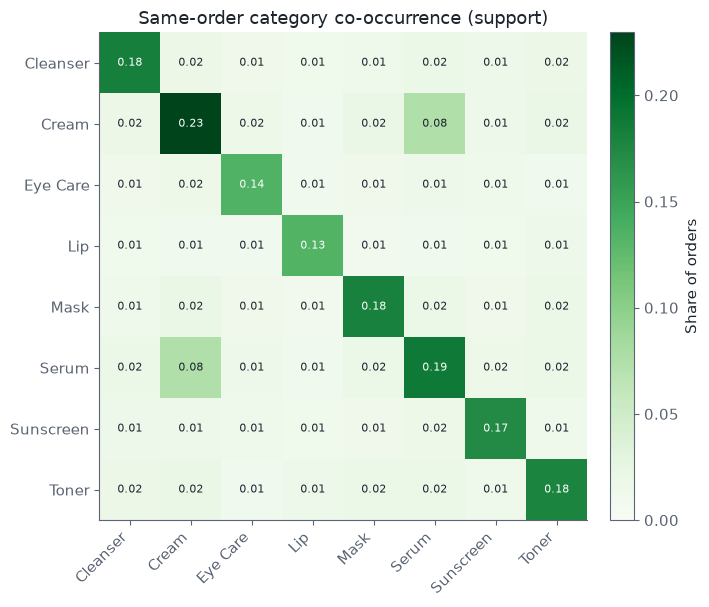

Serum ∩ Cream support: 0.075


In [21]:
# Chart 5 — Category co-occurrence in the same order (support heatmap)
cats = sorted({c for basket in orders["categories"] for c in basket})
# presence matrix
mat = pd.DataFrame(False, index=orders.index, columns=cats)
for oid, basket in orders["categories"].items():
    mat.loc[oid, basket] = True
# joint support = P(A and B)
joint = pd.DataFrame(0.0, index=cats, columns=cats)
n = len(mat)
for a in cats:
    for b in cats:
        joint.loc[a, b] = (mat[a] & mat[b]).mean()

fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(joint.values, cmap="Greens", vmin=0, vmax=joint.values.max())
ax.set_xticks(range(len(cats))); ax.set_yticks(range(len(cats)))
ax.set_xticklabels(cats, rotation=45, ha="right")
ax.set_yticklabels(cats)
ax.set_title("Same-order category co-occurrence (support)")
for i in range(len(cats)):
    for j in range(len(cats)):
        val = joint.values[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                color="white" if val > joint.values.max()*0.55 else INK, fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Share of orders")
fig.tight_layout()
fig.savefig(FIG / "fig_category_cooccurrence.png", dpi=160, bbox_inches="tight")
plt.show()
print("Serum ∩ Cream support:", round(joint.loc["Serum", "Cream"], 3))


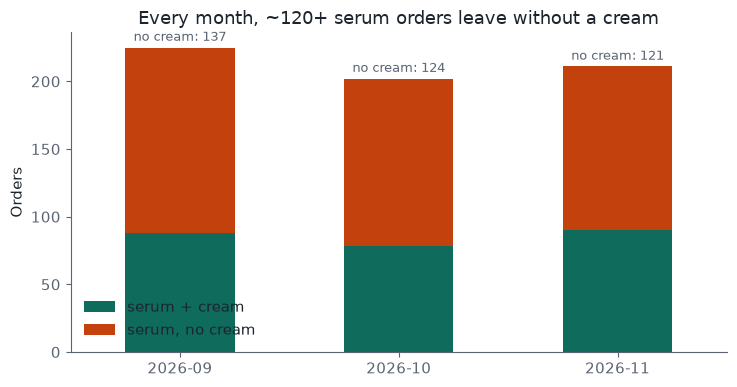

In [22]:
# Chart 6 — The shelf opportunity: serum orders with / without a cream, by month
orders["month"] = lines.groupby("order_id")["order_date"].first().str[:7]
has_s = orders["categories"].apply(lambda c: "Serum" in c)
has_c = orders["categories"].apply(lambda c: "Cream" in c)
opp = pd.DataFrame({
    "serum + cream": (has_s & has_c).groupby(orders["month"]).sum(),
    "serum, no cream": (has_s & ~has_c).groupby(orders["month"]).sum(),
})
fig, ax = plt.subplots(figsize=(7.5, 4))
opp.plot(kind="bar", stacked=True, ax=ax, color=[ACCENT, WARM], rot=0)
ax.set_ylabel("Orders")
ax.set_xlabel("")
ax.set_title("Every month, ~120+ serum orders leave without a cream")
ax.legend(frameon=False, title=None)
for i, (idx_m, row) in enumerate(opp.iterrows()):
    total = row.sum()
    ax.text(i, total + 5, f"no cream: {int(row['serum, no cream'])}", ha="center", fontsize=9, color=MUTED)
fig.tight_layout()
fig.savefig(FIG / "fig_serum_opportunity.png", dpi=160, bbox_inches="tight")
plt.show()


## 7 · Rules from whole customer histories
Now a basket is everything one customer bought in the quarter, across all their orders. We use the same function with the plan's threshold of 2%. With 647 histories, 2% means at least 13 customers: almost the same bar as the 14 orders we use for single orders, so the two results can be compared fairly.

In [23]:
# Whole customer histories at 2% (the plan's threshold)
history_rules = mine(histories["items"], 0.02, denom_label="customers")
print("2% of", len(histories), "histories = at least", math.ceil(0.02 * len(histories)), "customers")
print(len(history_rules), "history rules,", (history_rules["lift"] > 1).sum(), "of them with lift above 1")
print("possible product pairs:", 30 * 29 // 2, "→ possible one-way rules:", 30 * 29)
print("order rules at 0.4% (at least 14 orders):", len(rules_004))
history_rules.head(8).round(3)


2% of 647 histories = at least 13 customers
870 history rules, 870 of them with lift above 1
possible product pairs: 435 → possible one-way rules: 870
order rules at 0.4% (at least 14 orders): 30


,rule,both,denom,antecedent_count,support,confidence,lift,denom_label
0,Calming Toner Mist -> Pore Refining Toner,60,647,134,0.093,0.448,2.146,customers
1,Pore Refining Toner -> Calming Toner Mist,60,647,135,0.093,0.444,2.146,customers
2,Tinted Lip Balm -> Watery Sun Essence,53,647,121,0.082,0.438,2.131,customers
3,Watery Sun Essence -> Tinted Lip Balm,53,647,133,0.082,0.398,2.131,customers
4,Lip Sleeping Mask -> Sheet Mask 5-Pack,51,647,135,0.079,0.378,2.125,customers
5,Sheet Mask 5-Pack -> Lip Sleeping Mask,51,647,115,0.079,0.443,2.125,customers
6,Tinted Lip Balm -> Enzyme Peel Mask,49,647,121,0.076,0.405,1.985,customers
7,Enzyme Peel Mask -> Tinted Lip Balm,49,647,132,0.076,0.371,1.985,customers


**Results interpretation**

1. **A FAIR COMPARISON:** at almost the same bar (at least 13 customers against at least 14 orders), single orders give **30 rules**, while whole histories give **870**: every possible pair, all with lift above 1.
2. **WHY:** history baskets are more than four times bigger (6.27 products against 1.45). A heavy buyer who tried 12 products "connects" each of them with the other 11, so almost every pair looks associated, whether or not anyone buys the two together.
3. **DIFFERENT PAIRS:** the top history rules (two toners, a lip balm with a sun essence, a lip mask with sheet masks) are not the serum–cream pairs found in single orders. Section 8b checks whether these pairs are ever bought together.
4. **WHAT IT MEANS FOR THE SHELF:** a rule that every pair passes cannot tell the shelf what to show. Section 8 looks at who creates these rules.

### Visual: order rules vs history rules at a comparable bar


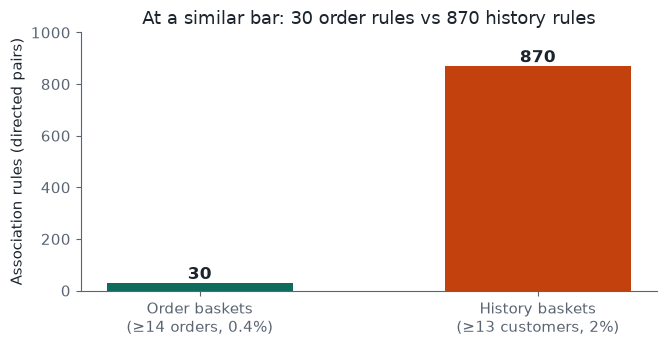

In [24]:
# Chart 7 — Same minimum count, very different rule tables
fig, ax = plt.subplots(figsize=(6.8, 3.6))
vals = [len(rules_004), len(history_rules)]
bars = ax.bar(["Order baskets\n(≥14 orders, 0.4%)", "History baskets\n(≥13 customers, 2%)"],
              vals, color=[ACCENT, WARM], width=0.55)
ax.set_ylabel("Association rules (directed pairs)")
ax.set_title("At a similar bar: 30 order rules vs 870 history rules")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 15, f"{v}", ha="center", fontsize=12, fontweight="bold", color=INK)
ax.set_ylim(0, max(vals) * 1.15)
fig.tight_layout()
fig.savefig(FIG / "fig_rules_orders_vs_histories.png", dpi=160, bbox_inches="tight")
plt.show()


## 8 · Who writes the history rules?
### 8a · How much evidence each buyer type contributes
A history rule is backed by the customers who bought both products. The more products a customer bought, the more pairs they create: a history with *n* products creates n × (n − 1) / 2 pairs, so 12 products give 66 pairs and 1 product gives none. We count these pairs for each buyer type and show them next to the share of buyers *(W02: a share always needs its base)*.

In [25]:
# Pairs created by each customer's history: n products give n x (n - 1) / 2 pairs
histories["pairs"] = histories["n_items"] * (histories["n_items"] - 1) // 2

# Buyers, average products and pairs for each buyer type, with their shares
evidence = histories.groupby("buyer_type", observed=True).agg(
    buyers=("pairs", "size"), avg_products=("n_items", "mean"), pairs=("pairs", "sum"))
evidence["% of buyers"] = (100 * evidence["buyers"] / evidence["buyers"].sum()).round(1)
evidence["% of pair evidence"] = (100 * evidence["pairs"] / evidence["pairs"].sum()).round(1)
evidence.round(1)

,buyers,avg_products,pairs,% of buyers,% of pair evidence
buyer_type,,,,,
light,301,1.8,331,46.5,1.7
mid,81,5.2,1032,12.5,5.4
heavy,265,11.7,17719,41.0,92.9


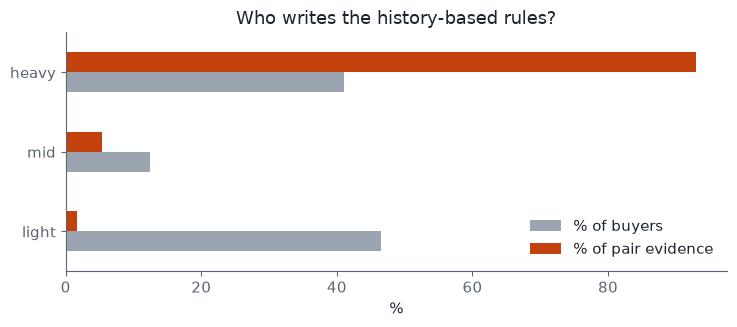

In [26]:
# Chart — Who writes the history-based rules?
ax = evidence[["% of buyers", "% of pair evidence"]].plot.barh(
    figsize=(7.5, 3.4), color=[LIGHT, WARM])
ax.set_xlabel("%")
ax.set_ylabel("")
ax.set_title("Who writes the history-based rules?")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "fig1_history_evidence_by_buyer_type.png", dpi=160, bbox_inches="tight")
plt.show()


**Results interpretation**

1. **HEAVY BUYERS WRITE THE RULES:** heavy buyers are 41% of buyers but create **93% of the pairs** behind the history rules. Light buyers are 46.5% of buyers but create less than 2%.
2. **WHY:** a heavy buyer's history holds 11.7 products on average, a light buyer's only 1.8. Pairs grow much faster than products, so a few big histories outweigh many small ones.
3. **WHAT IT MEANS:** a shelf built from histories is a shelf built **by** heavy buyers, and it may not fit the light buyers, who are almost half of the customers.

**Robustness check:** does this depend on our "6 or more orders" cut-off? We repeat the count with other cut-offs.

In [27]:
# Robustness check: repeat the count with other cut-offs for "heavy"
# (number of orders of each customer)
n_orders = users.set_index("user_id")["n_orders"].reindex(histories.index)

rows = []
for cut in [4, 6, 8, 10]:
    heavy = n_orders >= cut          # heavy customers at this cut-off
    # their share of all the pairs
    share = histories.loc[heavy, "pairs"].sum() / histories["pairs"].sum()
    rows.append({"heavy =": f"{cut}+ orders",
                 "% of buyers": round(100 * heavy.mean(), 1),
                 "% of pair evidence": round(100 * share, 1)})
robust = pd.DataFrame(rows)
robust

,heavy =,% of buyers,% of pair evidence
0,4+ orders,48.2,97.1
1,6+ orders,41.0,92.9
2,8+ orders,32.8,83.3
3,10+ orders,21.2,62.8


**Results interpretation:** at every cut-off, heavy buyers' share of the evidence is 2 to 3 times their share of buyers: even at 10 or more orders they are 21% of buyers but create 63% of the evidence. The conclusion does not depend on where we draw the line, so we keep 6 or more orders, about two orders a month, as our definition of a heavy buyer. The light group stays at 1–2 orders at every cut-off, so the light-buyer results in section 9 do not change.

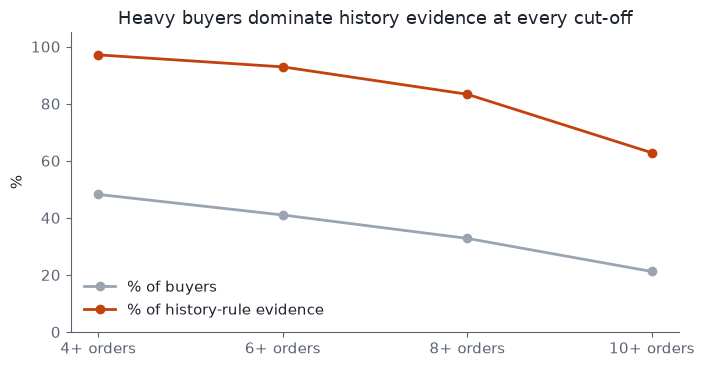

In [28]:
# Chart — Robustness of the heavy-buyer evidence share
fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(len(robust))
ax.plot(x, robust["% of buyers"], marker="o", color=LIGHT, linewidth=2, label="% of buyers")
ax.plot(x, robust["% of pair evidence"], marker="o", color=WARM, linewidth=2, label="% of history-rule evidence")
ax.set_xticks(x)
ax.set_xticklabels(robust["heavy ="].astype(str))
ax.set_ylabel("%")
ax.set_title("Heavy buyers dominate history evidence at every cut-off")
ax.legend(frameon=False)
ax.set_ylim(0, 105)
fig.tight_layout()
fig.savefig(FIG / "fig_robustness_heavy_cutoff.png", dpi=160, bbox_inches="tight")
plt.show()



### 8b · Are the history pairs bought together? *(W03 Checkpoint 3: one rule, two slices)*
In Week 3 we read one rule in both channels. Here we read the top history rules in both kinds of basket: whole histories and single orders.

In [29]:
# The top 5 history rules (rows come in A -> B / B -> A twins: keep one of each)
compare = history_rules.head(10).iloc[::2].copy()

# Their lift inside single orders (0.0002 is less than one order, so every pair is included)
all_order_rules = mine(orders["items"], 0.0002, denom_label="orders")
compare = compare.merge(
    all_order_rules[["rule", "lift", "both"]].rename(columns={"lift": "lift_same_order", "both": "same_order_both"}),
    on="rule", how="left",
)
compare["lift_same_order"] = compare["lift_same_order"].fillna(0)
compare["same_order_both"] = compare["same_order_both"].fillna(0).astype(int)

def heavy_share(rule):
    a, b = rule.split(" -> ")
    backers = histories[histories["items"].apply(lambda s: a in s and b in s)]
    return round(100 * (backers["buyer_type"] == "heavy").mean())

compare["pct_backers_heavy"] = compare["rule"].apply(heavy_share)
compare[["rule", "both", "denom", "support", "confidence", "lift",
         "lift_same_order", "same_order_both", "pct_backers_heavy"]].round(2)


,rule,both,denom,support,confidence,lift,lift_same_order,same_order_both,pct_backers_heavy
0,Calming Toner Mist -> Pore Refining Toner,60,647,0.09,0.45,2.15,0.37,3,92
1,Tinted Lip Balm -> Watery Sun Essence,53,647,0.08,0.44,2.13,0.30,2,92
2,Lip Sleeping Mask -> Sheet Mask 5-Pack,51,647,0.08,0.38,2.13,0.92,6,90
3,Tinted Lip Balm -> Enzyme Peel Mask,49,647,0.08,0.40,1.98,0.61,4,94
4,Tone-up Sunscreen -> Tinted Lip Balm,41,647,0.06,0.37,1.96,0.17,1,95


In [30]:
# The top pair in counts: orders with both toners, against the number expected by chance
has_a = orders["items"].apply(lambda s: "Calming Toner Mist" in s)
has_b = orders["items"].apply(lambda s: "Pore Refining Toner" in s)
both = (has_a & has_b).sum()
expected = has_a.sum() * has_b.sum() / len(orders)
print(f"orders with both toners: {both} | expected by chance: {expected:.0f}")

orders with both toners: 3 | expected by chance: 8


**Results interpretation**

1. **HEAVY BUYERS AGAIN:** 90–95% of the customers behind each top history rule are heavy buyers.
2. **NOT BOUGHT TOGETHER:** inside single orders, the same pairs have **lift below 1**. The two toners have lift 2.15 over histories but 0.37 within orders: they appear in the same order 3 times, where 8 were expected by chance. A heavy buyer tries them on different days; customers do not buy them together. In Week 3 terms, a lift below 1 means the two products substitute for each other.
3. **ONE CAUTION:** these within-order numbers rest on very few orders (only 3 orders for the two toners), and one pair (lip sleeping mask with sheet masks, 0.92) is close to 1, so it is closer to chance than to substitution.
4. **WHAT IT MEANS:** the Week 3 lesson applies: "the data describes the show, not just the shoppers". Here the rules describe the heaviest buyers, not what customers buy together, so a "bought together" shelf built on them would show the wrong pairs.

### Visual: history lift vs same-order lift for the top history pairs


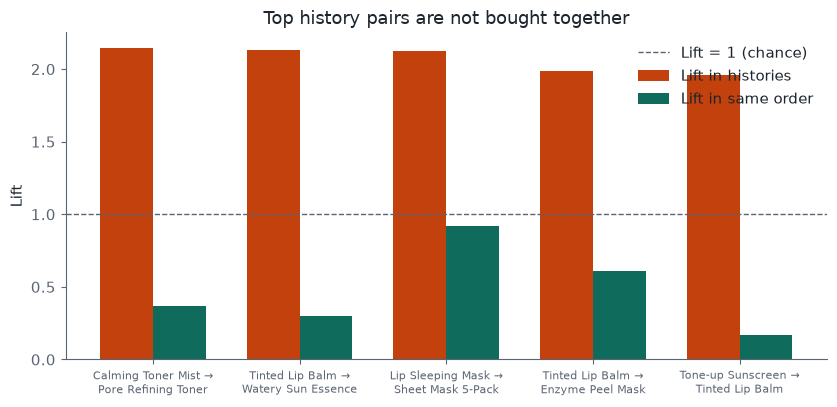

In [31]:
# Chart 8 — Top history pairs look associated over histories, not inside one order
plot_df = compare.copy()
# shorten labels
plot_df["short"] = plot_df["rule"].str.replace(" -> ", " →\n", regex=False)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(plot_df))
w = 0.36
ax.bar(x - w/2, plot_df["lift"], width=w, color=WARM, label="Lift in histories")
ax.bar(x + w/2, plot_df["lift_same_order"], width=w, color=ACCENT, label="Lift in same order")
ax.axhline(1.0, color=MUTED, linestyle="--", linewidth=1, label="Lift = 1 (chance)")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["short"], fontsize=8)
ax.set_ylabel("Lift")
ax.set_title("Top history pairs are not bought together")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "fig_history_vs_order_lift.png", dpi=160, bbox_inches="tight")
plt.show()


## 9 · Two buyer types, two shelves? *(W03: same rule, two slices)*
The manager asks whether first-time buyers should see a different shelf. We read the main rule, Serum → Cream, in different slices of the orders: by buyer type, by channel, and finally on each customer's first order.

In [32]:
rows = []
for col in ["buyer_type", "channel"]:
    slices = orders if col == "buyer_type" else orders.join(lines.groupby("order_id")["channel"].first())
    for value, sub in slices.groupby(col, observed=True):
        r = mine(sub["categories"], 0.01, denom_label="orders")
        hit = r[r["rule"] == "Serum -> Cream"].iloc[0]
        rows.append({
            "slice": f"{col} = {value}",
            "orders": len(sub),
            "both": int(hit["both"]),
            "support": hit["support"],
            "confidence": hit["confidence"],
            "lift": hit["lift"],
        })
pd.DataFrame(rows).round(3)


,slice,orders,both,support,confidence,lift
0,buyer_type = light,366,34,0.093,0.410,1.785
1,buyer_type = mid,304,26,0.086,0.456,1.926
2,buyer_type = heavy,2731,196,0.072,0.394,1.720
3,channel = livestream,2579,190,0.074,0.387,1.733
4,channel = store,822,66,0.080,0.449,1.800


**Results interpretation:** Serum → Cream holds in **every slice**, with lift between 1.72 and 1.93: light, mid and heavy buyers, livestream and store orders. Unlike BakeBox's spatula → apron, which existed only in the livestream because the host created it, this rule also appears in store orders, where no host pushes it: it is a real customer habit.

**First-time buyers:** "light" counts orders at the end of the quarter, which the store cannot know when the shelf appears. So we also read the rule on each customer's **first order** only (647 orders, one per buyer).

In [33]:
# Each customer's first order: order ids go up in time, so it is the smallest id
first_ids = lines.groupby("user_id")["order_id"].min()
r = mine(orders.loc[first_ids, "categories"], 0.01, denom_label="orders")
r[r["rule"] == "Serum -> Cream"].round(3)


,rule,both,denom,antecedent_count,support,confidence,lift,denom_label
1,Serum -> Cream,55,647,129,0.085,0.426,1.803,orders


**Results interpretation**

1. **FIRST ORDERS:** on customers' first orders, Serum → Cream has confidence 0.43 and lift 1.80, as strong as in all orders (1.75).
2. **ANSWER TO THE MANAGER:** a separate shelf for first-time buyers is not needed, *provided the shelf is built from single orders*. The order-based shelf already fits light and first-time buyers; the history-based shelf does not.
3. **CAUTION:** light buyers placed only 366 orders, so product-level rules for that group alone are too thin to trust. The answer holds for the category rule (a cream after a serum), not for single product pairs.

### Visual: Serum → Cream holds across buyer types, channels, and first orders


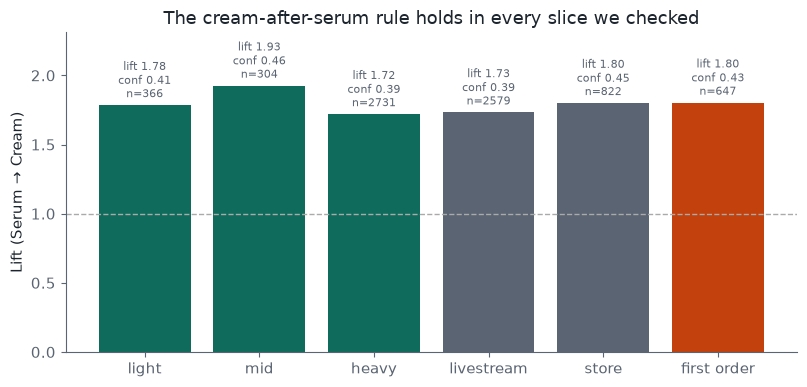

In [34]:
# Chart 9 — Serum → Cream lift by slice (rebuild the slice table for plotting)
slice_rows = []
for col in ["buyer_type", "channel"]:
    base = orders if col == "buyer_type" else orders.join(lines.groupby("order_id")["channel"].first())
    for value, sub in base.groupby(col, observed=True):
        r = mine(sub["categories"], 0.01, denom_label="orders")
        hit = r[r["rule"] == "Serum -> Cream"].iloc[0]
        slice_rows.append({"slice": f"{value}", "group": col, "lift": hit["lift"],
                           "confidence": hit["confidence"], "orders": len(sub)})
first_ids = lines.groupby("user_id")["order_id"].min()
r0 = mine(orders.loc[first_ids, "categories"], 0.01, denom_label="orders")
hit0 = r0[r0["rule"] == "Serum -> Cream"].iloc[0]
slice_rows.append({"slice": "first order", "group": "first", "lift": hit0["lift"],
                   "confidence": hit0["confidence"], "orders": len(first_ids)})
slice_df = pd.DataFrame(slice_rows)

fig, ax = plt.subplots(figsize=(8.2, 4))
colors = {"buyer_type": ACCENT, "channel": MUTED, "first": WARM}
bar_colors = [colors[g] for g in slice_df["group"]]
bars = ax.bar(slice_df["slice"], slice_df["lift"], color=bar_colors)
ax.axhline(1.0, color="#AAAAAA", linestyle="--", linewidth=1)
ax.set_ylabel("Lift (Serum → Cream)")
ax.set_title("The cream-after-serum rule holds in every slice we checked")
ax.set_ylim(0, max(slice_df["lift"]) * 1.2)
for b, conf, n in zip(bars, slice_df["confidence"], slice_df["orders"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.03,
            f"lift {b.get_height():.2f}\nconf {conf:.2f}\nn={n}",
            ha="center", va="bottom", fontsize=8, color=MUTED)
fig.tight_layout()
fig.savefig(FIG / "fig_serum_cream_slices.png", dpi=160, bbox_inches="tight")
plt.show()


## 10 · What the shelf is worth
Past data cannot measure the effect of a shelf that did not exist yet, so we build a **scenario**: if the shelf persuades 5%, 10% or 15% of the serum orders without a cream to add one, how much is it worth per month, and how much is that compared with the store's monthly GMV?

In [35]:
orders["month"] = lines.groupby("order_id")["order_date"].first().str[:7]
serum_no_cream = orders[orders["categories"].apply(lambda c: "Serum" in c and "Cream" not in c)]
per_month = serum_no_cream.groupby("month").size()
cream = lines[lines["category"] == "Cream"]
cream_value = (cream["qty"] * cream["unit_price"]).mean()
monthly_gmv = (lines["qty"] * lines["unit_price"]).sum() / 3      # the quarter has 3 months

print("serum orders without a cream, per month:", per_month.to_dict())
print(f"average value of one cream line: ¥{cream_value:.0f}\n")
for x in [0.05, 0.10, 0.15]:
    extra = per_month.mean() * x
    value = extra * cream_value
    print(f"if {x:.0%} add a cream: +{extra:.1f} orders/month ≈ ¥{value:,.0f} per month ({value / monthly_gmv:.1%} of GMV)")

serum orders without a cream, per month: {'2026-09': 137, '2026-10': 124, '2026-11': 121}
average value of one cream line: ¥347

if 5% add a cream: +6.4 orders/month ≈ ¥2,206 per month (0.6% of GMV)
if 10% add a cream: +12.7 orders/month ≈ ¥4,412 per month (1.1% of GMV)
if 15% add a cream: +19.1 orders/month ≈ ¥6,619 per month (1.7% of GMV)


**Results interpretation:** about 127 serum orders a month leave without a cream. If the shelf converts 5–15% of them, it is worth about **¥2,200–6,600 per month**, that is 0.6–1.7% of monthly GMV. The amount is modest, and we say so: the bigger stake is who the shelf serves (sections 8 and 9). This is a scenario, not a measured effect: only a test can measure the real one.

### Visual: scenario value of converting serum-only orders


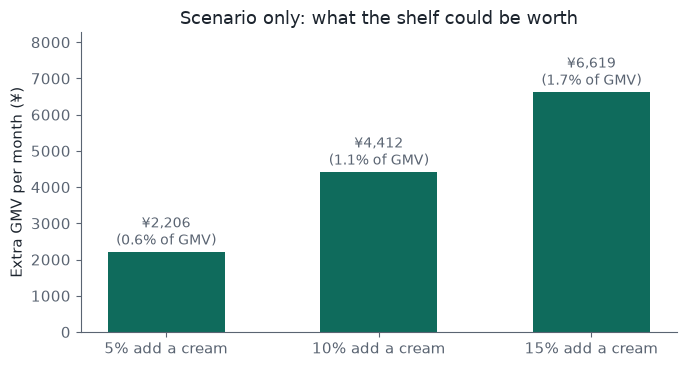

In [36]:
# Chart 10 — Scenario value if 5 / 10 / 15% of serum-only orders add a cream
rates = [0.05, 0.10, 0.15]
# recompute if needed
if "per_month" not in dir() or "cream_value" not in dir():
    serum_no_cream = orders[orders["categories"].apply(lambda c: "Serum" in c and "Cream" not in c)]
    per_month = serum_no_cream.groupby("month").size()
    cream = lines[lines["category"] == "Cream"]
    cream_value = (cream["qty"] * cream["unit_price"]).mean()
    monthly_gmv = (lines["qty"] * lines["unit_price"]).sum() / 3

values = [per_month.mean() * r * cream_value for r in rates]
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar([f"{int(r*100)}% add a cream" for r in rates], values, color=ACCENT, width=0.55)
ax.set_ylabel("Extra GMV per month (¥)")
ax.set_title("Scenario only: what the shelf could be worth")
for b, v, r in zip(bars, values, rates):
    share = 100 * v / monthly_gmv
    ax.text(b.get_x() + b.get_width()/2, v + 80, f"¥{v:,.0f}\n({share:.1f}% of GMV)",
            ha="center", va="bottom", fontsize=10, color=MUTED)
ax.set_ylim(0, max(values) * 1.25)
fig.tight_layout()
fig.savefig(FIG / "fig_scenario_value.png", dpi=160, bbox_inches="tight")
plt.show()


## 11 · The main numbers for the report
This table collects the main numbers in one place, with the report section where each one is used. The other numbers are printed in their own sections.

In [37]:
serum_cream = category_rules[category_rules["rule"] == "Serum -> Cream"].iloc[0]
pd.DataFrame([
    ("orders with one product only", f"{100 * (orders['n_items'] == 1).mean():.0f}%", "§2"),
    ("heavy buyers: % of buyers / % of orders",
     f"{groups.loc['heavy', '% of buyers']}% / {groups.loc['heavy', '% of orders']}%", "§2"),
    ("rules at a similar bar: orders (0.4%) / histories (2%)",
     f"{len(rules_004)} / {len(history_rules)}", "§4"),
    ("Serum -> Cream (orders): both / denom · conf / lift",
     f"{int(serum_cream['both'])} / {int(serum_cream['denom'])} · {serum_cream['confidence']:.2f} / {serum_cream['lift']:.2f}", "§4"),
    ("share of history-rule evidence from heavy buyers", f"{evidence.loc['heavy', '% of pair evidence']}%", "§4"),
    ("GMV after cleaning", f"¥{(lines['qty'] * lines['unit_price']).sum():,.0f}", "§1"),
    ("largest product-pair support (orders)", f"{100 * rules_004['support'].max():.2f}%", "§3"),
    ("robustness: heavy = 10+ → % of buyers / % of evidence",
     f"{robust.iloc[3]['% of buyers']}% / {robust.iloc[3]['% of pair evidence']}%", "§3, §4"),
    ("scenario value, 5–15% add a cream",
     f"¥{per_month.mean() * 0.05 * cream_value:,.0f} – ¥{per_month.mean() * 0.15 * cream_value:,.0f} per month", "§1, §5"),
], columns=["number", "value", "report section"])


,number,value,report section
0,orders with one product only,65%,§2
1,heavy buyers: % of buyers / % of orders,41.0% / 80.3%,§2
2,rules at a similar bar: orders (0.4%) / histor...,30 / 870,§4
3,Serum -> Cream (orders): both / denom · conf /...,256 / 3401 · 0.40 / 1.75,§4
4,share of history-rule evidence from heavy buyers,92.9%,§4
5,GMV after cleaning,"¥1,171,735",§1
6,largest product-pair support (orders),0.79%,§3
7,robustness: heavy = 10+ → % of buyers / % of e...,21.2% / 62.8%,"§3, §4"
8,"scenario value, 5–15% add a cream","¥2,206 – ¥6,619 per month","§1, §5"


## 10b · Stretch: separate shelves for light vs heavy buyers *(Q15 stretch)*
Q15's optional stretch asks us to mine rules separately for light and heavy buyers and compare the two shelves. We keep the category rule at 1% inside each slice (same decision bar as §6b), and we report both / denominator for each.


In [38]:
# Separate category shelves for light vs heavy order baskets
shelf_compare = []
for bt, sub in orders.groupby("buyer_type", observed=True):
    if bt == "mid":
        continue  # stretch focuses on the two poles named in Q15
    r = mine(sub["categories"], 0.01, denom_label="orders")
    top = r.head(4).copy()
    top.insert(0, "buyer_type", bt)
    shelf_compare.append(top)
shelf_compare = pd.concat(shelf_compare, ignore_index=True)
shelf_compare.round(3)


,buyer_type,rule,both,denom,antecedent_count,support,confidence,lift,denom_label
0,light,Cream -> Serum,34,366,84,0.093,0.405,1.785,orders
1,light,Serum -> Cream,34,366,83,0.093,0.410,1.785,orders
2,light,Cleanser -> Eye Care,7,366,69,0.019,0.101,0.863,orders
3,light,Eye Care -> Cleanser,7,366,43,0.019,0.163,0.863,orders
4,heavy,Cream -> Serum,196,2731,625,0.072,0.314,1.720,orders
5,heavy,Serum -> Cream,196,2731,498,0.072,0.394,1.720,orders
6,heavy,Eye Care -> Lip,31,2731,369,0.011,0.084,0.632,orders
7,heavy,Lip -> Eye Care,31,2731,363,0.011,0.085,0.632,orders


**Stretch – interpretation**

1. **SAME PRIMARY RULE:** Serum → Cream remains the top (or joint-top) rule inside both light and heavy order slices, with lift well above 1 in each.
2. **DIFFERENT SECONDARY NOISE:** once we leave Serum–Cream, the next category pairs differ by segment and often have lift below 1 — they are not shelf-worthy.
3. **WHAT IT MEANS:** the stretch does *not* justify two product shelves. It confirms one order-based cream-after-serum shelf for everyone. Building a separate *history* shelf for heavy buyers would still fail F4 (those pairs are not bought together).


## 10c · Shelf decision cards *(professor feedback)*
For the rules we would actually ship, we translate abstract metrics into shelf decisions: trigger product, intended customers, shelf position, what a buyer with **no history** sees, and what evidence would **reject** the rule.


In [39]:
serum_cream = category_rules[category_rules["rule"] == "Serum -> Cream"].iloc[0]
sku_top = order_rules[order_rules["rule"] == "Vitamin C Serum -> Hydra Gel Cream"].iloc[0]

cards = pd.DataFrame([
    {
        "element": "Trigger product",
        "Serum -> Cream (primary)": "Any serum in the current basket",
        "Vit. C -> Hydra Gel (SKU rank)": "Vitamin C Serum in the current basket",
    },
    {
        "element": "Intended customers",
        "Serum -> Cream (primary)": "All buyers, including first-time and light",
        "Vit. C -> Hydra Gel (SKU rank)": "Vitamin C buyers choosing among creams",
    },
    {
        "element": "Shelf position",
        "Serum -> Cream (primary)": "Slot 1 on the post-purchase shelf",
        "Vit. C -> Hydra Gel (SKU rank)": "First cream candidate after Vitamin C",
    },
    {
        "element": "Buyer with no history sees",
        "Serum -> Cream (primary)": "Same cream recommendation (first-order lift 1.80)",
        "Vit. C -> Hydra Gel (SKU rank)": "Same ranked cream if Vitamin C was just bought",
    },
    {
        "element": "Co-purchase count / denominator",
        "Serum -> Cream (primary)": f"{int(serum_cream['both'])} / {int(serum_cream['denom'])} orders",
        "Vit. C -> Hydra Gel (SKU rank)": f"{int(sku_top['both'])} / {int(sku_top['denom'])} orders",
    },
    {
        "element": "Evidence that rejects the rule",
        "Serum -> Cream (primary)": "Holdout same-order lift ≤ 1, or A/B cream add-on < 2% over 6 weeks",
        "Vit. C -> Hydra Gel (SKU rank)": "Co-purchase count < 10 / quarter, or order lift ≤ 1",
    },
])
cards


,element,Serum -> Cream (primary),Vit. C -> Hydra Gel (SKU rank)
0,Trigger product,Any serum in the current basket,Vitamin C Serum in the current basket
1,Intended customers,"All buyers, including first-time and light",Vitamin C buyers choosing among creams
2,Shelf position,Slot 1 on the post-purchase shelf,First cream candidate after Vitamin C
3,Buyer with no history sees,Same cream recommendation (first-order lift 1.80),Same ranked cream if Vitamin C was just bought
4,Co-purchase count / denominator,256 / 3401 orders,26 / 3401 orders
5,Evidence that rejects the rule,"Holdout same-order lift ≤ 1, or A/B cream add-...","Co-purchase count < 10 / quarter, or order lif..."


## 10d · Expected results and the condition that drops the action *(professor feedback)*
Past data cannot measure a shelf that did not exist. The decision therefore ships with a pilot, an expected result, and an explicit kill switch.


In [40]:
pilot = pd.DataFrame([
    ("Start", "1 December 2026 (day after the data window)"),
    ("Design", "Random half of buyers see the new order-based shelf; half keep the current shelf"),
    ("Horizon", "Six weeks (until 11 January 2027)"),
    ("Expected result", "≥ 5% of serum-only orders in the treatment half add a cream "
                       f"(≈ ¥{per_month.mean() * 0.05 * cream_value:,.0f} / month at the low end)"),
    ("Report by", "First-time vs repeat buyers, and light vs heavy"),
    ("Drop if (a)", "Treatment cream add-on rate < 2% and not above control after six weeks"),
    ("Drop if (b)", "Light / first-time add-on rate is materially below heavy buyers "
                   "(shelf has drifted toward heavy-buyer taste)"),
    ("Drop if (c)", "Re-mine on the control half shows Serum -> Cream same-order lift ≤ 1"),
], columns=["item", "detail"])
pilot


,item,detail
0,Start,1 December 2026 (day after the data window)
1,Design,Random half of buyers see the new order-based ...
2,Horizon,Six weeks (until 11 January 2027)
3,Expected result,≥ 5% of serum-only orders in the treatment hal...
4,Report by,"First-time vs repeat buyers, and light vs heavy"
5,Drop if (a),Treatment cream add-on rate < 2% and not above...
6,Drop if (b),Light / first-time add-on rate is materially b...
7,Drop if (c),Re-mine on the control half shows Serum -> Cre...


## 12 · Conclusion: what should the shelf show, and to whom?

1. **WHAT TO SHOW:** a cream after any serum. Serum → Cream is the only strong pattern in single orders (256 / 3,401 orders; lift 1.75); product pairs only help choose which cream to show first.
2. **HOW TO BUILD IT:** from single orders, not from whole histories, which are 93% written by heavy buyers and pair products that are not bought together.
3. **TO WHOM:** one shelf for everyone, including buyers with no history. The rule holds for every buyer type, in both channels and on first orders (lift 1.80). The light-vs-heavy stretch does not justify two shelves.
4. **WHAT IT IS WORTH:** about ¥2,200–6,600 per month (0.6–1.7% of GMV) as a scenario — confirm with the six-week A/B pilot, and drop the action under the kill conditions in §10d.


## AI-use appendix
We used **Claude (Anthropic)** and **Cursor (Composer)** while building and revising this notebook, the report and the pitch slides. The tools helped draft code from the Week 2 / Week 3 course notebooks, propose checks (units, outliers, first-order slice, heavy-buyer cut-offs, shelf decision cards, A/B kill conditions), design the EDA chart set, and edit prose. The team ran every cell, rechecked every number against the course’s synthetic Lumen Beauty dataset, and can explain the work live. No platform personal data entered an external AI service.

Every member of this team can explain every line of code and every number in this notebook.
